# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
# from google.colab import files  (not needed, I ran it locally)

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # X is (questions, words), so batch_first is needed
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        out, _ = self.rnn(self.emb(x))
        scores = self.att(out).masked_fill((x == 0).unsqueeze(-1), -1e9)  # padding gets no attention
        weights = torch.softmax(scores, dim=1)
        return self.fc((out * weights).sum(1)), weights.squeeze(-1)

model = RNN()

**Note:** I changed two things in the original model. `nn.RNN` expects (words, batch, features) by default, but `X` is (questions, words), so without `batch_first=True` the RNN was reading across the 168 questions and not across the words of one question. I also masked the padding so the zeros at the end don't take any of the attention.

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear the gradients from the last step
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

with torch.no_grad():
    predictions, all_weights = model(X)
print("Training finished!")
print(f"Final loss: {loss.item():.4f}")
print(f"Training accuracy: {(predictions.argmax(1) == y).float().mean().item():.4f}")

Training finished!
Final loss: 0.0688
Training accuracy: 0.9881


I also added `optimizer.zero_grad()`, otherwise the gradients keep adding up from every epoch.

## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

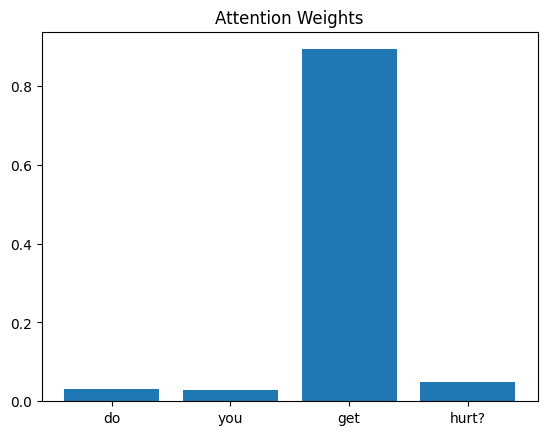

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [7]:
def plot_attention(question):
    question = question.lower()
    i = df.index[df["question"] == question][0]
    words = [tokenizer.index_word[t] for t in X[i].tolist() if t != 0]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    weights = weights[0, :len(words)].tolist()

    top = words[weights.index(max(weights))]
    print("Question:", question)
    print("Predicted answer:", df["answer"][df["answer_id"] == prediction.argmax().item()].iloc[0])
    print(f"Highest attention: '{top}' ({max(weights):.2f})")

    plt.bar(words, weights)
    plt.title(f"Attention Weights: {question}")
    plt.ylim(0, 1)
    plt.show()

Question: what kind of food do you eat?
Predicted answer: I don't need to eat.
Highest attention: 'eat' (0.71)


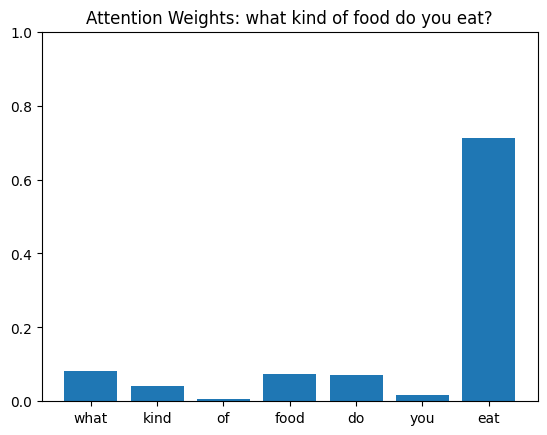

In [8]:
plot_attention("What kind of food do you eat?")

Question: how old are you?
Predicted answer: Age doesn't really apply to me.
Highest attention: 'old' (0.69)


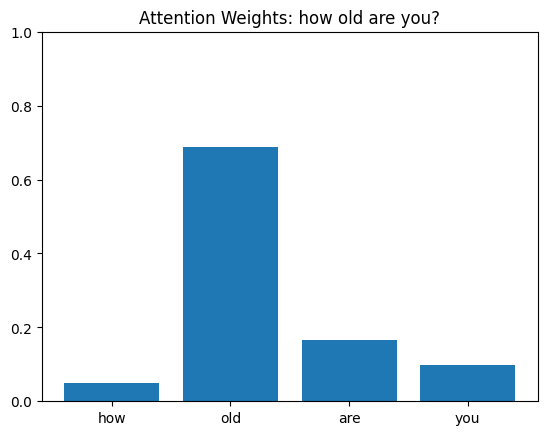

In [9]:
plot_attention("How old are you?")

Question: so what is your name?
Predicted answer: I don't have a name.
Highest attention: 'so' (0.94)


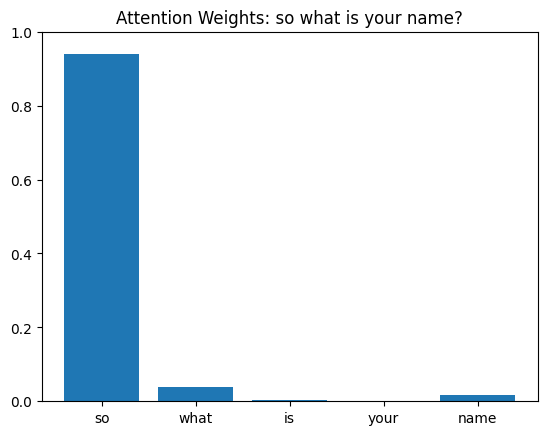

In [10]:
plot_attention("So what is your name?")

**Answer:**

| Question | Highest attention |
|---|---|
| What kind of food do you eat? | eat (0.71) |
| How old are you? | old (0.69) |
| So what is your name? | so (0.94) |

In the first two questions, yes. "eat" and "old" are the words that tell you what the question is about, and the model got the right answer for both. Words like "what", "of", "do" and "you" got very small weights, which makes sense because they show up in almost every question.

The third one is different. The model put almost all the attention on "so" and not on "name". When I checked the dataset, every question that starts with "so" belongs to the name group, so the model learned a shortcut from this small dataset and doesn't really understand the question. The answer is still correct, but for the wrong reason. So the highest attention is not always the most important word for a human.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: what do you think about ai?
Predicted answer: The world of technology is fascinating.
Highest attention: 'think' (0.91)


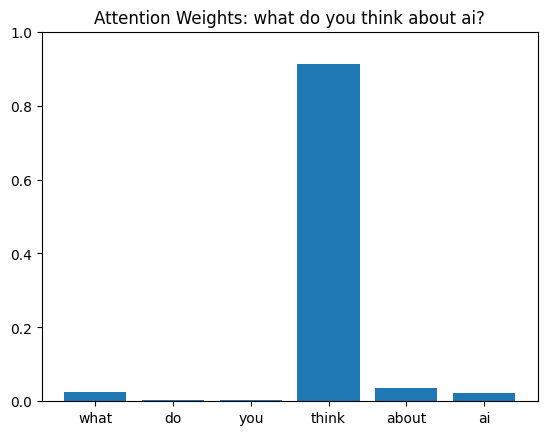

In [11]:
plot_attention("What do you think about AI?")

Question: what is your opinion about ai?
Predicted answer: The world of technology is fascinating.
Highest attention: 'opinion' (0.96)


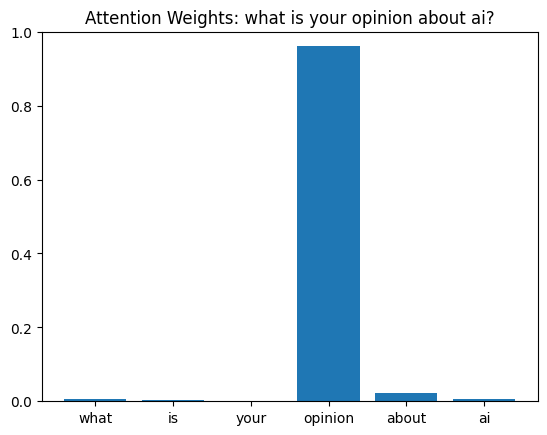

In [12]:
plot_attention("What is your opinion about AI?")

**Answer:**

| Question | Highest attention |
|---|---|
| What do you think about AI? | think (0.91) |
| What is your opinion about AI? | opinion (0.96) |

The model focused on different words, "think" in one and "opinion" in the other, but both words do the same job in the question: they show that the person is asking what the bot thinks. In both questions "AI" and "about" got almost nothing, even though they are the same in the two questions, and both were given the correct answer.

This suggests that attention doesn't look for the same exact word. It looks for the word that is most useful for picking the answer, and since the RNN learned that "think" and "opinion" lead to the same answer group, they both end up getting the attention. The attention is also learned only from this dataset, so it picks whatever separates the answer groups best (like "so" in Task 1), which isn't always the word a person would pick.